# **Dependencies**

In [ ]:
%pip install torchcam

In [13]:
import kagglehub
from datasets import load_dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import torch
import torchvision
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torch.utils.data import random_split
from torchvision.datasets import ImageFolder
from torch.utils.data import ConcatDataset
from torchvision.models import resnet18, ResNet18_Weights

from torchcam.methods import SmoothGradCAMpp
from torchvision.transforms.functional import to_pil_image
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    f1_score,
    fbeta_score
)

In [ ]:
!pip freeze | grep -E "torch|torchvision|datasets|pandas|scikit-learn|matplotlib|seaborn|torchcam" > requirements.txt

# **Model training**

In [ ]:
# 1) Selección de dispositivo (GPU/CPU)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Usando device:", device)

Usando device: cuda


In [ ]:
# 2) Carga de datos y redistribución de splits

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

## No hacemos acciones más específicas porque vamos a redistribuir train test val
base_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = ImageFolder(
    root="/kaggle/input/chest-xray-pneumonia/chest_xray/train",
    transform=base_transform
)

test_dataset = ImageFolder(
    root="/kaggle/input/chest-xray-pneumonia/chest_xray/test",
    transform=base_transform
)

val_dataset = ImageFolder(
    root="/kaggle/input/chest-xray-pneumonia/chest_xray/val",
    transform=base_transform
)

## El dataset viene con un split hecho, pero val solo tiene 16 imágenes, por lo que vamos a juntar
## todo en un único dataset para hacer una redistribución más equilibrada

full_dataset = ConcatDataset([train_dataset, val_dataset, test_dataset])

total_size = len(full_dataset)

train_size = int(0.70 * total_size)
val_size   = int(0.15 * total_size)
test_size  = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [ ]:
# 3) Definición de DataLoaders

TAM_LOTE = 32 # 32 imágenes por lote

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=TAM_LOTE,
    shuffle=True,
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=TAM_LOTE,
    shuffle=False,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=TAM_LOTE,
    shuffle=False,
)

In [ ]:
# 4) Carga del modelo, congelación de todas las capas salvo la última y montaje del modelo en el dispositivo

# Número de clases: neumonía o sano
NUM_CLASSES = 2

# ResNet18 preentrenada
modelo = resnet18(weights=ResNet18_Weights.DEFAULT)

in_features = modelo.fc.in_features

# Congelar todas las capas 
for param in modelo.parameters():
    param.requires_grad = False

# Sustituir capa final para modificarla: fine-tuning
modelo.fc = nn.Linear(in_features, NUM_CLASSES)

modelo = modelo.to(device)

In [ ]:
# 5) Definición de hiperparámetros, loss function y optimizador
TASA_APRENDIZAJE = 3e-4
EPOCHS = 10

fn_perdida = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=TASA_APRENDIZAJE)

In [ ]:
# 6) Train loop, Val loop y Test loop

## Uso de data augmentation para robustez
augmentation_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
])

def train_loop(dataloader, model, loss_fn, optimizer):
    train_size = len(dataloader.dataset)
    nlotes = len(dataloader)

    model.train()

    perdida_train, exactitud = 0.0, 0.0

    all_preds = []
    all_labels = []

    for nlote, (X, y) in enumerate(dataloader):

        X = torch.stack([
            augmentation_transform(img) for img in X
        ])

        X, y = X.to(device), y.to(device)

        logits = model(X)

        # Predicciones
        _, preds = torch.max(logits, 1)

        # Guardar métricas
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        perdida_train += loss.item()
        exactitud += (logits.argmax(1) == y).float().sum().item()

        if nlote % 10 == 0:
            ndatos = nlote * TAM_LOTE
            print(f"\tPérdida: {loss.item():>7f}  [{ndatos:>5d}/{train_size:>5d}]")

    perdida_train /= max(nlotes, 1)
    exactitud /= max(train_size, 1)

    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    f2 = fbeta_score(all_labels, all_preds, beta=2)

    print("\n\tEntrenamiento:")
    print(f"\tAccuracy : {(100*exactitud):.2f}%")
    print(f"\tLoss     : {perdida_train:.4f}")
    print(f"\tPrecision: {precision:.4f}")
    print(f"\tRecall   : {recall:.4f}")
    print(f"\tF1-score : {f1:.4f}")
    print(f"\tF2-score : {f2:.4f}")

    return {
        "loss": perdida_train,
        "accuracy": exactitud,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f2": f2
    }

def val_loop(dataloader, model, loss_fn):
    val_size = len(dataloader.dataset)
    nlotes = len(dataloader)

    model.eval()

    perdida_val, exactitud = 0.0, 0.0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            logits = model(X)

            _, preds = torch.max(logits, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

            perdida_val += loss_fn(logits, y).item()
            exactitud += (preds == y).float().sum().item()

    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    f2 = fbeta_score(all_labels, all_preds, beta=2)
    cm = confusion_matrix(all_labels, all_preds)

    perdida_val /= max(nlotes, 1)
    exactitud /= max(val_size, 1)

    print("\n\tValidación:")
    print(f"\tAccuracy : {(100*exactitud):.2f}%")
    print(f"\tLoss     : {perdida_val:.4f}")
    print(f"\tPrecision: {precision:.4f}")
    print(f"\tRecall   : {recall:.4f}")
    print(f"\tF1-score : {f1:.4f}")
    print(f"\tF2-score : {f2:.4f}")

    return {
        "loss": perdida_val,
        "accuracy": exactitud,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f2": f2,
        "cm": cm
    }


def test_loop(model, test_loader, device):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    f2 = fbeta_score(all_labels, all_preds, beta=2)
    cm = confusion_matrix(all_labels, all_preds)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f2": f2
    }, cm

In [ ]:
# 7) Loop de entrenamiento y guardado del mejor modelo

best_epoch = None
best_val_f2 = 0

for epoch in range(EPOCHS):

    print(f"\nIteración {epoch+1}/{EPOCHS}")
    print("-"*30)

    train_metrics = train_loop(
        train_loader,
        modelo,
        fn_perdida,
        optimizador
    )

    val_metrics = val_loop(
        val_loader,
        modelo,
        fn_perdida
    )

    f2 = val_metrics["f2"]
    ## guardamos un checkpoint de cada modelo
    if f2 > best_val_f2:  # F2
        best_val_f2 = f2
        best_epoch = epoch
        best_state = modelo.state_dict()

        print(f"✔ Nuevo mejor modelo en epoch {epoch+1} (F2={f2:.4f})")

torch.save(best_state, "best_model.pth")


Iteración 1/10
------------------------------
	Pérdida: 0.346947  [    0/ 4099]
	Pérdida: 0.368492  [  320/ 4099]
	Pérdida: 0.429702  [  640/ 4099]
	Pérdida: 0.354696  [  960/ 4099]
	Pérdida: 0.246004  [ 1280/ 4099]
	Pérdida: 0.302482  [ 1600/ 4099]
	Pérdida: 0.231590  [ 1920/ 4099]
	Pérdida: 0.397939  [ 2240/ 4099]
	Pérdida: 0.346238  [ 2560/ 4099]
	Pérdida: 0.328665  [ 2880/ 4099]
	Pérdida: 0.300684  [ 3200/ 4099]
	Pérdida: 0.355702  [ 3520/ 4099]
	Pérdida: 0.293233  [ 3840/ 4099]

	Entrenamiento:
	Accuracy : 86.26%
	Loss     : 0.3304
	Precision: 0.8657
	Recall   : 0.9617
	F1-score : 0.9112
	F2-score : 0.9408

	Validación:
	Accuracy : 89.29%
	Loss     : 0.2974
	Precision: 0.9688
	Recall   : 0.8803
	F1-score : 0.9224
	F2-score : 0.8967
✔ Nuevo mejor modelo en epoch 1 (F2=0.8967)

Iteración 2/10
------------------------------
	Pérdida: 0.293922  [    0/ 4099]
	Pérdida: 0.187282  [  320/ 4099]
	Pérdida: 0.238057  [  640/ 4099]
	Pérdida: 0.317745  [  960/ 4099]
	Pérdida: 0.213081  [ 128

In [ ]:
# 8) Carga del mejor modelo

## Rehacer arquitectura exacta del modelo
modelo = resnet18(weights=ResNet18_Weights.DEFAULT)
in_features = modelo.fc.in_features
modelo.fc = nn.Linear(in_features, 2)  # nº de clases: 2
modelo = modelo.to(device)

## Cargar checkpoint
state_dict = torch.load("best_model.pth", map_location=device)

modelo.load_state_dict(state_dict)

## Poner en modo evaluación
modelo.eval()

Accuracy:  93.6%
Precision: 96.5%
Recall:    94.7%
F2 Score:  95.0%


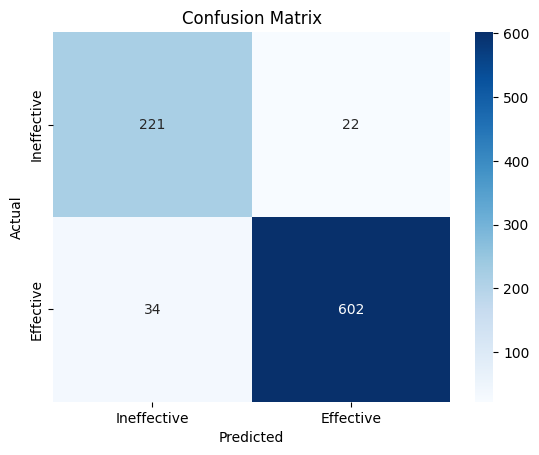

In [ ]:
# 9) Predicciones sobre el test split
final_metrics, cm = test_loop(modelo, test_loader, device)

print(f"Accuracy:  {final_metrics['accuracy']*100:.1f}%")
print(f"Precision: {final_metrics['precision']*100:.1f}%")
print(f"Recall:    {final_metrics['recall']*100:.1f}%")
print(f"F2 Score:  {final_metrics['f2']*100:.1f}%")

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
           xticklabels=["Ineffective", "Effective"],
           yticklabels=["Ineffective", "Effective"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# **Grad-CAM**

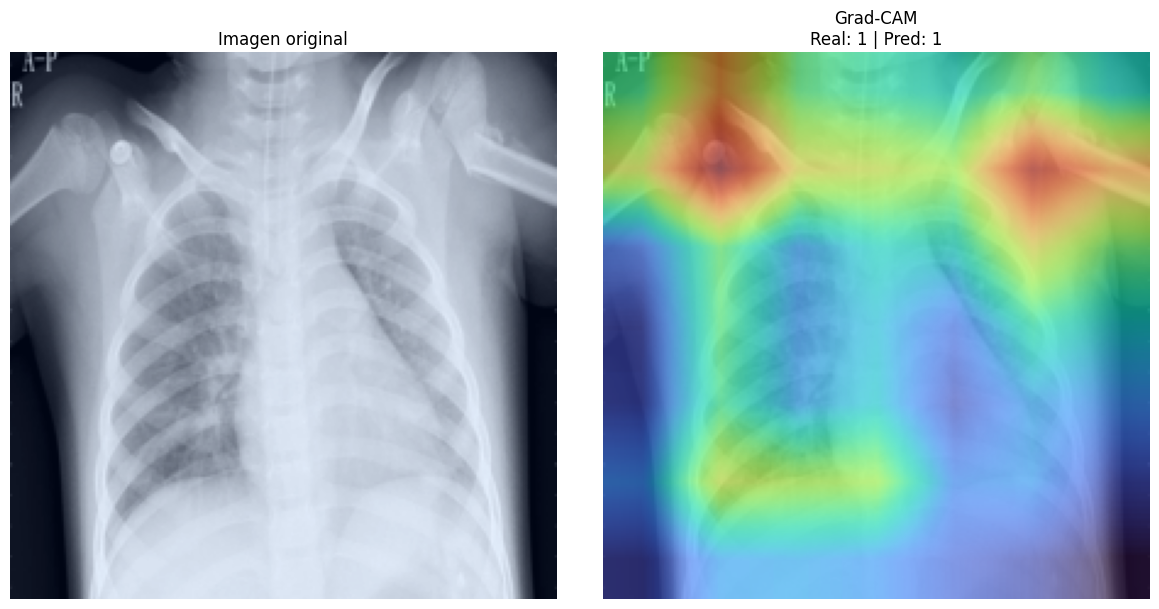

In [27]:
# 1) Tomamos un batch
Xb, yb = next(iter(train_loader))
img_tensor = Xb[0:1].to(device)  # (1,3,224,224)
img_tensor.requires_grad_()
target_class = yb[0].item()

# 2) Crear extractor
cam_extractor = SmoothGradCAMpp(modelo, target_layer='layer4')

# Forward
logits = modelo(img_tensor)
pred_class = logits.argmax(1).item()

# 3) Obtener heatmap
activation_map = cam_extractor(pred_class, logits)
heatmap = activation_map[0].squeeze(0)  # (H,W)

# 4) Redimensionar a 224x224
heatmap_tensor = heatmap.unsqueeze(0).unsqueeze(0)
heatmap_resized = F.interpolate(
    heatmap_tensor,
    size=(224,224),
    mode='bilinear',
    align_corners=False
)

heatmap_resized = heatmap_resized.squeeze().cpu().numpy()

# 5) Convertir imagen a PIL (desnormalizando ligeramente)
img = img_tensor[0].cpu()
img = (img - img.min()) / (img.max() - img.min())
img_pil = to_pil_image(img).convert("RGB")

# 6) Visualizar
fig, axes = plt.subplots(1, 2, figsize=(12,6))

# Imagen original
axes[0].imshow(img_pil)
axes[0].axis('off')
axes[0].set_title("Imagen original")

# Imagen con Grad-CAM
axes[1].imshow(img_pil)
axes[1].imshow(heatmap_resized, cmap='turbo', alpha=0.6)
axes[1].axis('off')
axes[1].set_title(f'Grad-CAM\nReal: {target_class} | Pred: {pred_class}')

plt.tight_layout()
plt.show()

cam_extractor.remove_hooks()